In [35]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

df=pd.read_csv("../data/vehicles_cleaned.csv")

print("Dataset loaded successflly")


print("Dataset shape:", df.shape)

df.head()




Dataset loaded successflly
Dataset shape: (45094, 29)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,image_url,description,state,lat,long,posting_date,listing_year,vehicle_age,mileage_category,price_category
0,7316814884,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,33590,2014,gmc,sierra 1500 crew cab slt,good,8 cylinders,...,https://images.craigslist.org/00R0R_lwWjXSEWNa...,Carvana is the safer way to buy a car During t...,al,32.590,-85.4800,2021-05-04 17:31:18+00:00,2021,7.0,Low,Expensive
1,7316814758,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,22590,2010,chevrolet,silverado 1500,good,8 cylinders,...,https://images.craigslist.org/00R0R_lwWjXSEWNa...,Carvana is the safer way to buy a car During t...,al,32.590,-85.4800,2021-05-04 17:31:08+00:00,2021,11.0,Medium,Mid-Range
2,7316814989,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,39590,2020,chevrolet,silverado 1500 crew,good,8 cylinders,...,https://images.craigslist.org/01212_jjirIWa0y0...,Carvana is the safer way to buy a car During t...,al,32.590,-85.4800,2021-05-04 17:31:25+00:00,2021,1.0,Very Low,Expensive
3,7316743432,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,30990,2017,toyota,tundra double cab sr,good,8 cylinders,...,https://images.craigslist.org/00x0x_1y9kIOzGCF...,Carvana is the safer way to buy a car During t...,al,32.590,-85.4800,2021-05-04 15:41:31+00:00,2021,4.0,Low,Expensive
4,7316356412,https://auburn.craigslist.org/cto/d/auburn-uni...,auburn,https://auburn.craigslist.org,15000,2013,ford,f-150 xlt,excellent,6 cylinders,...,https://images.craigslist.org/00404_l4loxHvdQe...,2013 F-150 XLT V6 4 Door. Good condition. Leve...,al,32.592,-85.5189,2021-05-03 19:02:03+00:00,2021,8.0,High,Mid-Range


In [36]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())


Column names:
['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'state', 'lat', 'long', 'posting_date', 'listing_year', 'vehicle_age', 'mileage_category', 'price_category']

Missing values in each column:
id                      0
url                     0
region                  0
region_url              0
price                   0
year                    0
manufacturer            0
model                   0
condition               0
cylinders               0
fuel                    0
odometer               45
title_status            0
transmission            0
VIN                 17312
drive                   0
size                    0
type                    0
paint_color             0
image_url               0
description             1
state                   0
lat                     0
long          

In [31]:
# Missing value ar chart


missing=df.isnull().sum()

missing=missing[missing>0].sort_values(ascending=False)

print(missing)





VIN                 17312
odometer               45
mileage_category       45
vehicle_age             2
description             1
dtype: int64


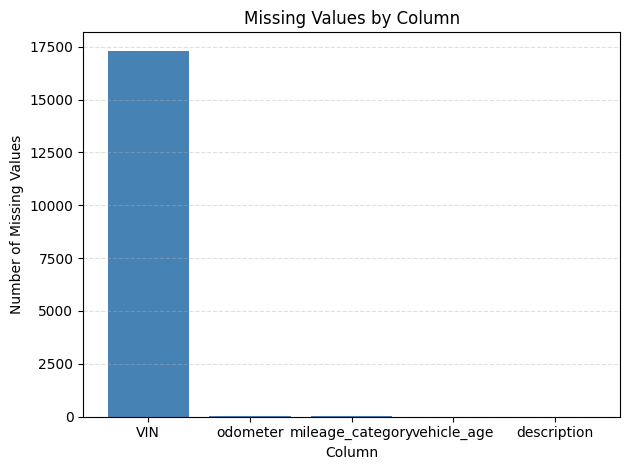

In [32]:

bars=plt.bar(

    missing.index,
    missing.values,
    color="steelblue"
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()



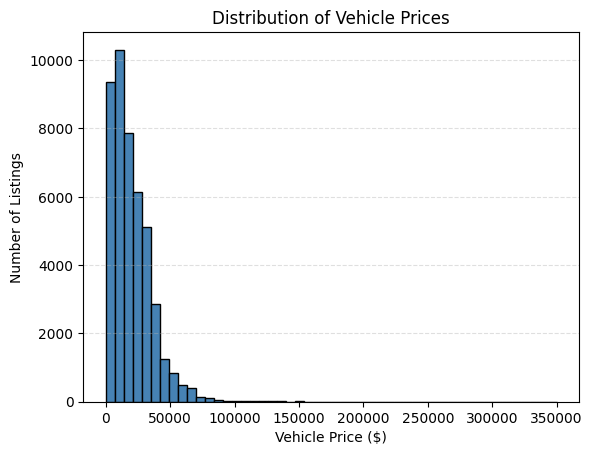

In [33]:
# Vehicle Price Histogram.


plt.hist(df["price"], bins=50,color="steelblue", edgecolor="black")

plt.title("Distribution of Vehicle Prices")

plt.xlabel("Vehicle Price ($)")

plt.ylabel("Number of Listings")

plt.grid(axis="y",linestyle="--", alpha=0.4)

plt.show()

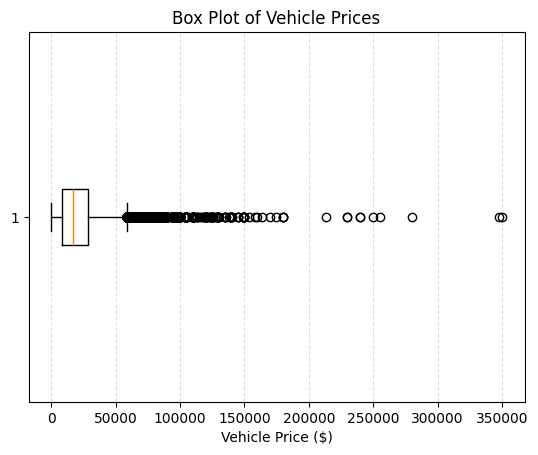

In [34]:
plt.boxplot(df["price"].dropna(), vert=False)

plt.title("Box Plot of Vehicle Prices")

plt.xlabel("Vehicle Price ($)")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.show()


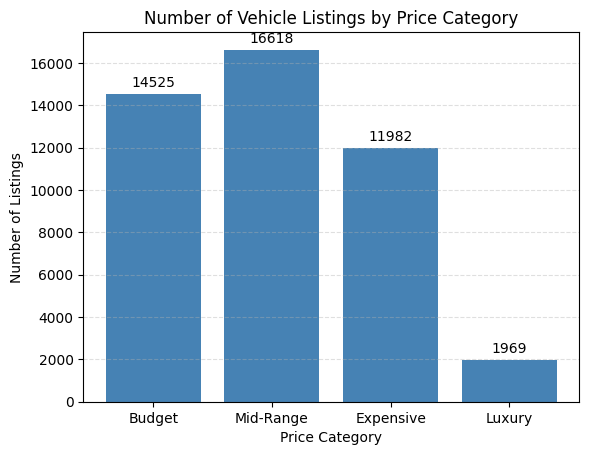

In [16]:
# Listings by Price Category

categories=["Budget", "Mid-Range", "Expensive", "Luxury"]
listings=[14525,16618,11982,1969]

bars=plt.bar(categories,listings,color="steelblue")

plt.title("Number of Vehicle Listings by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Listings")

plt.bar_label(bars,padding=3)
plt.grid(axis="y",linestyle="--",alpha=0.4)

plt.show()

In [17]:
top_manufacturers=df["manufacturer"].value_counts().head(10)

print(top_manufacturers)

manufacturer
ford             7020
chevrolet        5800
toyota           4093
honda            2221
nissan           2194
unknown          1979
ram              1836
bmw              1685
jeep             1651
mercedes-benz    1611
Name: count, dtype: int64


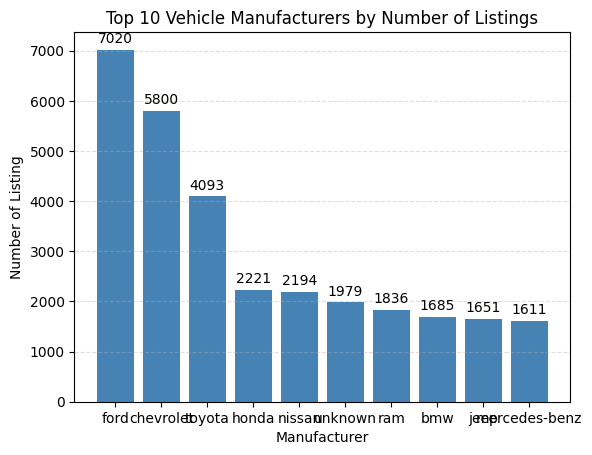

In [18]:
bars=plt.bar(
    top_manufacturers.index,
    top_manufacturers.values,
    color="steelblue"   
)

plt.title("Top 10 Vehicle Manufacturers by Number of Listings")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Listing")



plt.bar_label(bars,padding=3)

plt.grid(axis="y",linestyle="--", alpha=0.4)
plt.show()



In [22]:
#  Average Price by Manufacturer


avg_price=(

    df.groupby("manufacturer")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print(avg_price.round(2))


manufacturer
ferrari         159773.76
aston-martin    109944.00
porsche          35447.49
tesla            34943.47
ram              31479.62
alfa-romeo       30238.03
rover            28989.33
jaguar           27255.21
gmc              25911.77
audi             24966.30
Name: price, dtype: float64


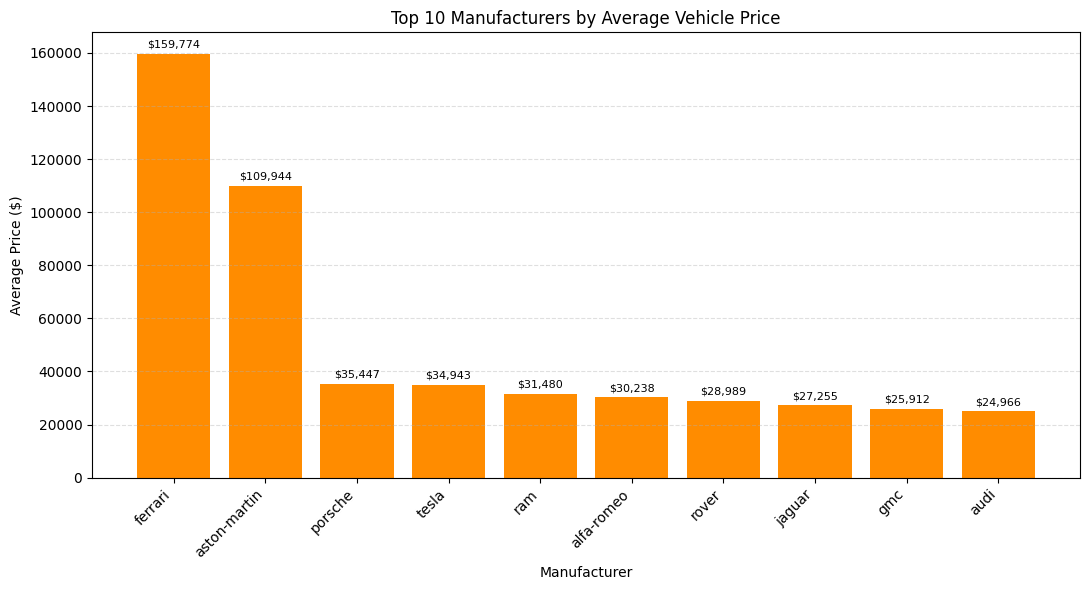

In [23]:

plt.figure(figsize=(11, 6))

bars = plt.bar(
    avg_price.index,
    avg_price.values,
    color="darkorange"
)

plt.title("Top 10 Manufacturers by Average Vehicle Price")
plt.xlabel("Manufacturer")
plt.ylabel("Average Price ($)")

plt.xticks(rotation=45, ha="right")
plt.bar_label(
    bars,
    labels=[f"${value:,.0f}" for value in avg_price.values],
    padding=3,
    fontsize=8
)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [24]:
# Odometer Histogram

print(df["odometer"].describe())

count      45049.000000
mean       89571.633777
std        72812.452253
min            0.000000
25%        35036.000000
50%        79345.000000
75%       127036.000000
max      1000000.000000
Name: odometer, dtype: float64


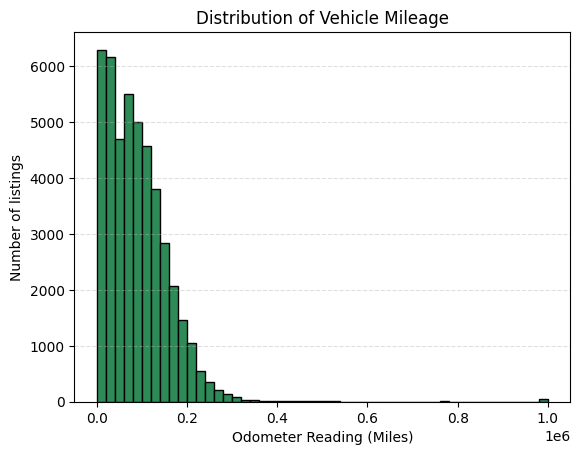

In [26]:
plt.hist(
    df["odometer"].dropna(),
    bins=50,
    color="seagreen",
    edgecolor="black"
)

plt.title("Distribution of Vehicle Mileage")
plt.xlabel("Odometer Reading (Miles)")
plt.ylabel("Number of listings")

plt.grid(axis="y",linestyle="--", alpha=0.4)


plt.show()

In [27]:

mileage_counts=df["mileage_category"].value_counts()

print(mileage_counts)

mileage_category
High         14787
Medium       10654
Very Low      9587
Low           7632
Very High     2389
Name: count, dtype: int64


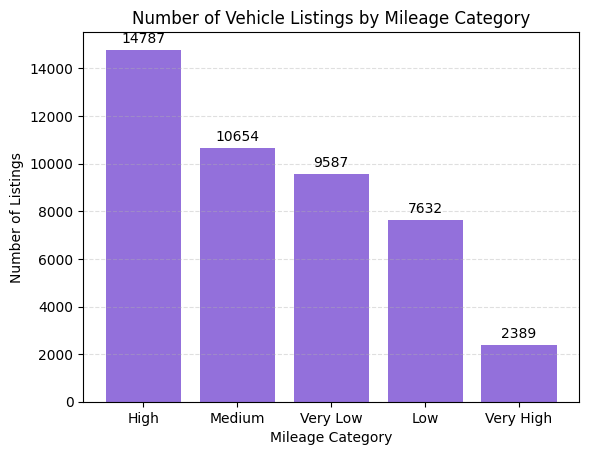

In [28]:
# Listings by Mileage Category
bars=plt.bar(
    mileage_counts.index,
    mileage_counts.values,
    color="mediumpurple"
)

plt.title("Number of Vehicle Listings by Mileage Category")
plt.xlabel("Mileage Category")
plt.ylabel("Number of Listings")


plt.bar_label(bars,padding=3)
plt.grid(axis="y",linestyle="--",alpha=0.4)

plt.show()

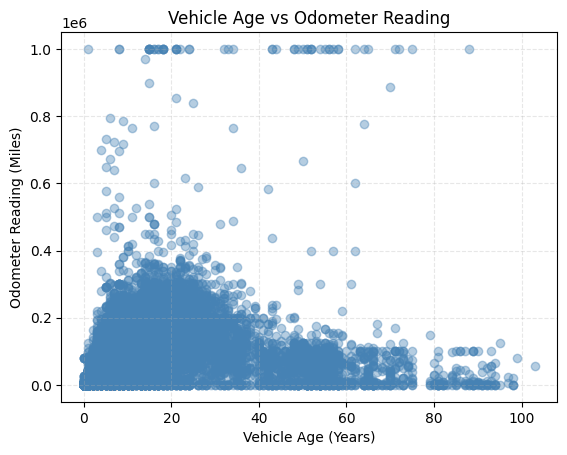

In [37]:
# Vehicle Age vs Odometer Scatter Plot

plt.scatter(

    df["vehicle_age"],
    df["odometer"],
    color="steelblue",
    alpha=0.4,
)

plt.title("Vehicle Age vs Odometer Reading")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Odometer Reading (Miles)")

plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

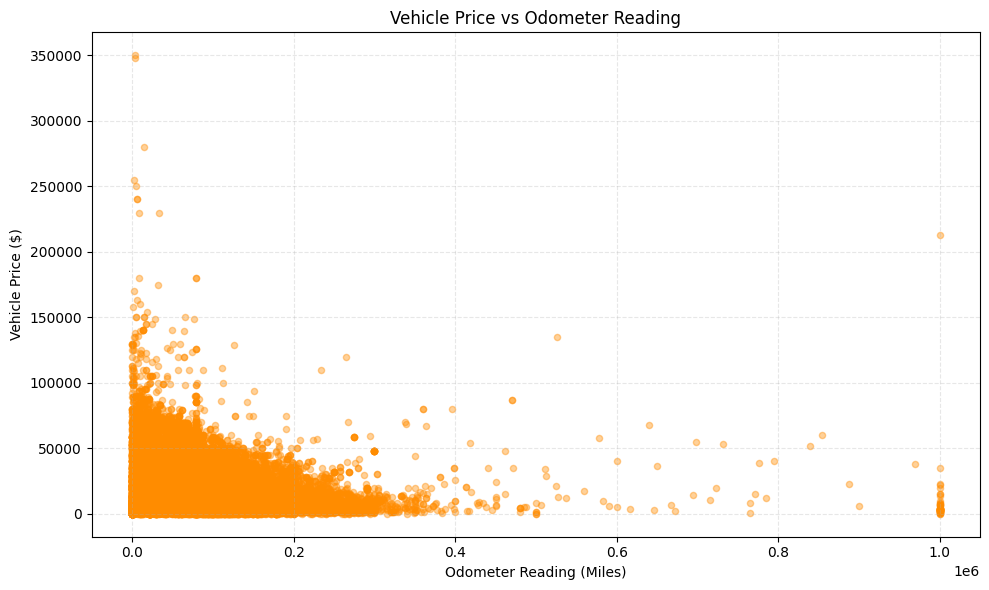

In [38]:
# Price vs Odometer Scatter Plot


plt.figure(figsize=(10, 6))

plt.scatter(
    df["odometer"],
    df["price"],
    color="darkorange",
    alpha=0.4,
    s=20
)

plt.title("Vehicle Price vs Odometer Reading")
plt.xlabel("Odometer Reading (Miles)")
plt.ylabel("Vehicle Price ($)")

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [40]:
# Vehicle Dataset Correlation Heatmap


numeric_df=df[["price", "year", "odometer", "vehicle_age"]]

correlation=numeric_df.corr()

print(correlation.round(2))

             price  year  odometer  vehicle_age
price         1.00  0.28      -0.4        -0.28
year          0.28  1.00      -0.3        -1.00
odometer     -0.40 -0.30       1.0         0.30
vehicle_age  -0.28 -1.00       0.3         1.00


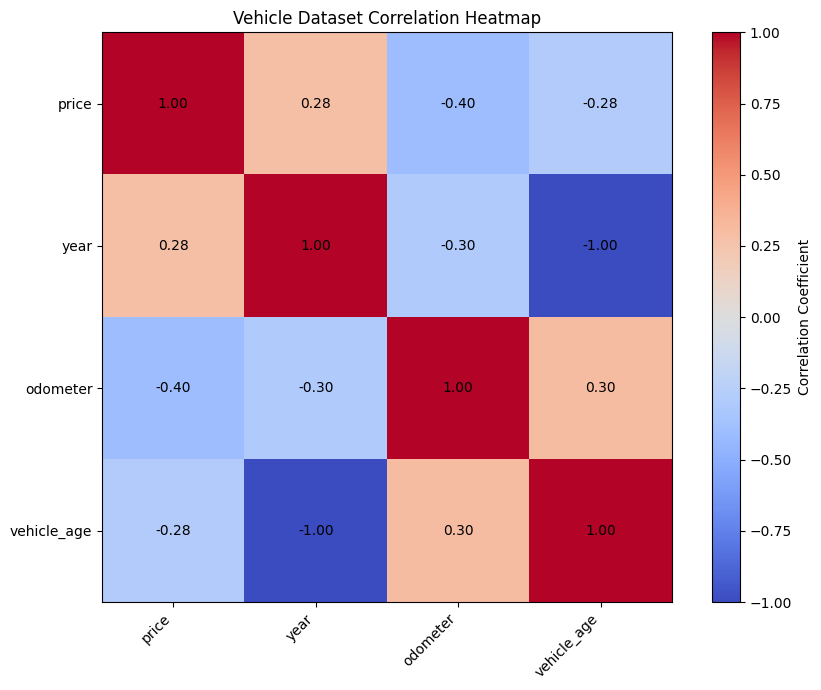

In [41]:

plt.figure(figsize=(9, 7))

plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Vehicle Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()
